# Supervised autoencoder on the T = 48 benign + GridSybil windows (T48_tvt)

The ConvAutoencoder of `task/autoencoder_overlap/` (input 14 × 48 = 13 features + mask, z = 16, 71,741 parameters)
with a small **classifier head on z** (Linear 16→32 → ReLU → Dropout 0.2 → Linear 32→1, 577 parameters; 72,318 in
total). Loss = class-weighted BCE (`pos_weight` = n_benign / n_gridsybil of the **train** split) + λ · masked MSE on
real rows (λ = `recon_weight` = 1). Data: `src/data/encoder_input/benign_gridsybil/T48_tvt/` (no overlap), with the
train / val / test split (80 / 10 / 10 by sender vehicle) fixed on disk.

Labels are used in training (supervised). The val split drives the LR schedule, early stopping, the best checkpoint
and both alarm thresholds (max F1 on val; benign FPR 5% on val). The test split is never read by `train.py`; here it
is read in section 4, and its labels only after every test window has been scored.

This notebook runs from the repo root, imports the package classes and reads the run folder written by
`npm run aest:train`. Sections: 1 input, 2 model, 3 training record, 4 test, 5 comparison, 6 analysis. Not the thesis
TimesNet model.

Setup: repo-root check, package imports, the run folder (the newest `runs/*/summary.json`).

In [1]:
import json
from pathlib import Path

assert Path("task/autoencoder_st/config.py").is_file(), "run this notebook from the repo root"

from task.autoencoder_st.config import SupervisedAEConfig, TOTAL_PARAMS
from task.autoencoder_st.data import WindowDataset
from task.autoencoder_st.metrics import TrackScores, ranking_metrics, threshold_metrics
from task.autoencoder_st.model import SupervisedAutoencoder, count_params
from task.autoencoder_st.trainer import Trainer

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve

settings = SupervisedAEConfig()
runs = sorted(Path(settings.runs_dir).glob("*/summary.json"), key=lambda p: p.stat().st_mtime)
assert runs, "no finished run: npm run aest:train"
RUN = runs[-1].parent
META = json.loads((Path(settings.data_dir) / "metadata.json").read_text())
FEATURES = META["features"]
print("run folder:", RUN)
print("data:", settings.data_dir)

run folder: task/autoencoder_st/runs/seed0
data: src/data/encoder_input/benign_gridsybil/T48_tvt


## 1. Input

The three splits as written on disk. Sender vehicles never cross splits (checked below). Class counts for train and
val; every track (one link = one receiver hearing one sender pseudonym) has a single label (checked). Test labels are
not read in this section.

In [2]:
splits = {
    name: WindowDataset.load(settings.data_dir, name, workers=settings.workers) for name in ("train", "val", "test")
}
train, val, test = splits["train"], splits["val"], splits["test"]
veh = {name: set(d.vehicles) for name, d in splits.items()}
assert not (veh["train"] & veh["val"]) and not (veh["train"] & veh["test"]) and not (veh["val"] & veh["test"])
tracks = {name: TrackScores(d.tracks) for name, d in splits.items()}
rows = []
for name in ("train", "val"):
    d = splits[name]
    for cls, v in (("Benign", 0), ("GridSybil", 1)):
        s = d.y == v
        rows.append(
            {
                "split": name,
                "class": cls,
                "windows": int(s.sum()),
                "tracks": len(set(d.tracks[s])),
                "sender vehicles": len(set(d.vehicles[s])),
            }
        )
counts = pd.DataFrame(rows).pivot(index="split", columns="class").loc[["train", "val"]]
counts[("windows", "total")] = counts["windows"].sum(axis=1)
print("no sender vehicle in two splits:", True)
print("tracks with mixed labels:", {name: tracks[name].track_labels(splits[name].y)[1] for name in ("train", "val")})
print(
    f"test (labels not read here): {len(test):,} windows, {len(tracks['test']):,} tracks, {len(veh['test']):,} sender vehicles"
)
counts

no sender vehicle in two splits: True
tracks with mixed labels: {'train': 0, 'val': 0}
test (labels not read here): 40,469 windows, 35,957 tracks, 574 sender vehicles


windows            tracks           sender vehicles           windows
class  Benign GridSybil  Benign GridSybil          Benign GridSybil   total
split                                                                      
train  112890    203160  101399    181813            3223      1380  316050
val     13584     25748   12218     22810             402       173   39332

Split diagram: windows per split (benign + GridSybil), with the number of sender vehicles behind each split.

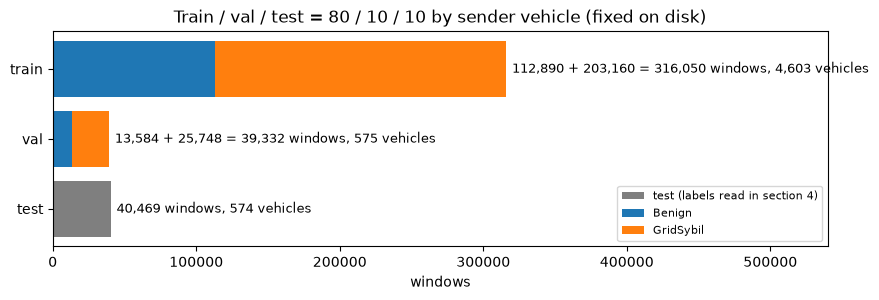

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.barh(0, len(test), color="tab:grey", label="test (labels read in section 4)")
ax.text(len(test) + 4000, 0, f"{len(test):,} windows, {len(veh['test']):,} vehicles", va="center", fontsize=9)
for y, name in ((1, "val"), (2, "train")):
    b, g = counts.loc[name, ("windows", "Benign")], counts.loc[name, ("windows", "GridSybil")]
    ax.barh(y, b, color="tab:blue", label="Benign" if y == 1 else None)
    ax.barh(y, g, left=b, color="tab:orange", label="GridSybil" if y == 1 else None)
    ax.text(b + g + 4000, y, f"{b:,} + {g:,} = {b + g:,} windows, {len(veh[name]):,} vehicles", va="center", fontsize=9)
ax.set_yticks(range(3), ["test", "val", "train"])
ax.set_xlim(0, 540000)
ax.set_xlabel("windows")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Train / val / test = 80 / 10 / 10 by sender vehicle (fixed on disk)")
plt.show()

Shape and padding: each window is 48 messages (1 Hz) × 13 normalised features, padding rows zero, the mask marks real
rows; the model gets the mask as a 14th channel (**14 × 48**). The class weight of the BCE comes from the train counts.

window x: (48, 13) + mask: (48,) -> model input: (14, 48)


,min,median,mean,max,share = 48,padding share,GridSybil share
split,,,,,,,
train,1,13.0,17.59,48,0.107,0.633,0.643
val,1,13.0,17.63,48,0.113,0.633,0.655
test,1,13.0,17.94,48,0.115,0.626,(section 4)


pos_weight = n_benign / n_gridsybil (train) = 112,890 / 203,160 = 0.5557  (run: 0.5557)


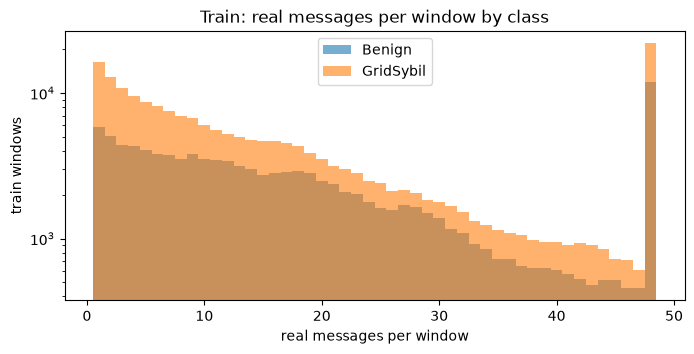

In [4]:
print(
    "window x:",
    train.x.shape[1:],
    "+ mask:",
    train.mask.shape[1:],
    "-> model input:",
    (settings.n_features + 1, settings.seq_len),
)
rows = []
for name, d in splits.items():
    n = d.n_messages
    rows.append(
        {
            "split": name,
            "min": n.min(),
            "median": np.median(n),
            "mean": round(n.mean(), 2),
            "max": n.max(),
            "share = 48": round(float((n == 48).mean()), 3),
            "padding share": round(1 - d.mask.mean(), 3),
            "GridSybil share": round(float(d.y.mean()), 3) if name != "test" else "(section 4)",
        }
    )
display(pd.DataFrame(rows).set_index("split"))
n_b, n_g = int((train.y == 0).sum()), int((train.y == 1).sum())
pos_weight = n_b / n_g
summary = json.loads((RUN / "summary.json").read_text())
print(
    f"pos_weight = n_benign / n_gridsybil (train) = {n_b:,} / {n_g:,} = {pos_weight:.4f}  "
    f"(run: {summary['pos_weight']:.4f})"
)
assert np.isclose(pos_weight, summary["pos_weight"])

fig, ax = plt.subplots(figsize=(8, 3.5))
for v, name in ((0, "Benign"), (1, "GridSybil")):
    ax.hist(train.n_messages[train.y == v], bins=np.arange(1, 50) - 0.5, alpha=0.6, label=name)
ax.set_xlabel("real messages per window")
ax.set_ylabel("train windows")
ax.set_yscale("log")
ax.legend()
ax.set_title("Train: real messages per window by class")
plt.show()

## 2. Model

Layers with their output shapes for one batch of 2 windows, including the classifier head, and the trainable
parameter count (asserted against 72,318).

In [5]:
model = SupervisedAutoencoder(settings)
x0, m0 = torch.zeros(2, settings.seq_len, settings.n_features), torch.ones(2, settings.seq_len, dtype=torch.bool)
table = []
layer_types = (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear, torch.nn.Dropout)
hooks = [
    mod.register_forward_hook(
        lambda mod, inp, out, name=name: table.append(
            (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))
        )
    )
    for name, mod in model.named_modules()
    if isinstance(mod, layer_types)
]
model.eval()
with torch.no_grad():
    recon0, z0, logit0 = model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"]))
print("reconstruction:", tuple(recon0.shape[1:]), " z:", tuple(z0.shape[1:]), " logit:", tuple(logit0.shape[1:]))
print(
    f"trainable parameters: {count_params(model):,} = autoencoder {count_params(model.autoencoder):,} "
    f"+ head {count_params(model.head):,}"
)
assert count_params(model) == TOTAL_PARAMS == summary["params"]

,layer,type,output (per window),params
0,autoencoder.encoder_conv.0,Conv1d,"(32, 48)",1376
1,autoencoder.encoder_conv.3,Conv1d,"(64, 24)",6208
2,autoencoder.encoder_conv.6,Conv1d,"(64, 12)",12352
3,autoencoder.to_z,Linear,"(16,)",12304
4,autoencoder.from_z,Linear,"(768,)",13056
5,autoencoder.decoder_conv.1,ConvTranspose1d,"(64, 24)",16448
6,autoencoder.decoder_conv.4,ConvTranspose1d,"(32, 48)",8224
7,autoencoder.decoder_conv.7,Conv1d,"(13, 48)",1261
8,head.net.0,Linear,"(32,)",544
9,head.net.2,Dropout,"(32,)",0


reconstruction: (48, 13)  z: (16,)  logit: ()
trainable parameters: 72,318 = autoencoder 71,741 + head 577


## 3. Training record

What `task.autoencoder_st.train` wrote: the summary (without the threshold tables), the per-epoch history re-plotted
(losses train vs val; val AUROC / PR-AUC / F1 @ 0.5; LR and gradient norm), and log lines. Train metrics are computed
from the running epoch outputs (train mode: dropout on, weights changing within the epoch), so train and val metrics
are not strictly comparable.

{
  "run_id": "seed0",
  "params": 72318,
  "best_epoch": 44,
  "best_val_auroc": 0.9267963801046768,
  "epochs_run": 54,
  "stop_reason": "early_stopping",
  "lr_changes": [
    {
      "after_epoch": 33,
      "from": 0.001,
      "to": 0.0005
    },
    {
      "after_epoch": 43,
      "from": 0.0005,
      "to": 0.00025
    },
    {
      "after_epoch": 50,
      "from": 0.00025,
      "to": 0.000125
    }
  ],
  "train_seconds": 329.5,
  "train_windows": 316050,
  "val_windows": 39332,
  "train_tracks": 283212,
  "val_tracks": 35028,
  "class_counts": {
    "train": {
      "benign": 112890,
      "gridsybil": 203160
    },
    "val": {
      "benign": 13584,
      "gridsybil": 25748
    }
  },
  "pos_weight": 0.5556704075605434,
  "threshold_source": "val split",
  "wall_seconds": 338.8,
  "device": "mps"
}
best epoch val metrics: {'loss': 0.3602, 'bce': 0.2012, 'recon': 0.159, 'auroc': 0.9268, 'pr_auc': 0.9684, 'f1': 0.8921, 'balanced_accuracy': 0.8922}


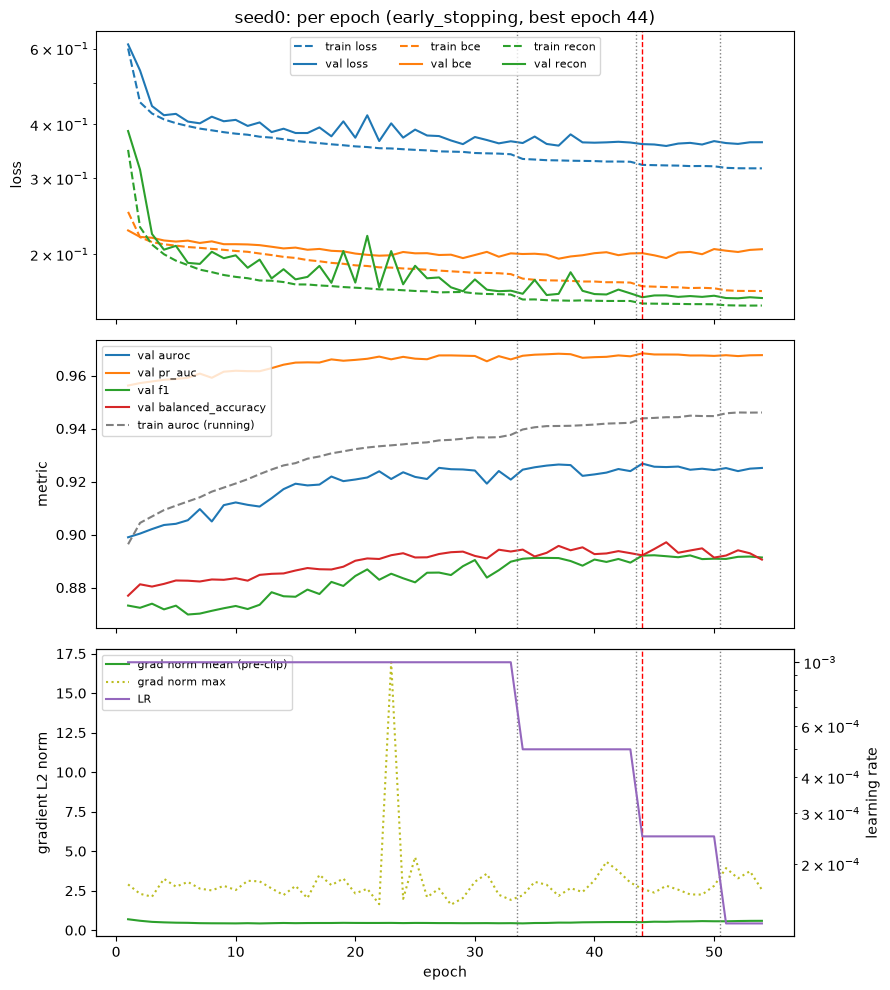

2026-10-28T16:51:04 checks: labels 0 / 1 with both classes in train and val; no shared sender vehicle; one label per track
2026-10-28T16:51:05 train 316,050 / val 39,332 windows (8s to load), shape (48, 13) + mask; vehicles 4,603 / 575; tracks 283,212 / 35,028; classes {"train": {"benign": 112890, "gridsybil": 203160}, "val": {"benign": 13584, "gridsybil": 25748}}; pos_weight = n_benign / n_gridsybil (train) = 0.5557
2026-10-28T16:51:05 padding share train 0.633 / val 0.633
2026-10-28T16:51:05 SupervisedAutoencoder: 72,318 trainable parameters (autoencoder 71,741 + head 577), input 14 x 48, z 16
2026-10-28T16:51:05 fit: 316,050 windows, val: 39,332 windows, batch 256, device mps, pos_weight 0.5557, recon_weight 1, grad_clip 1, early stopping on val AUROC (min_delta 0.0001 absolute, patience 10)
...
2026-10-28T16:51:12 epoch   1  loss 0.6000/0.6134  bce 0.2508/0.2272  recon 0.3492/0.3862  auroc 0.8964/0.8990  pr_auc 0.9563  f1 0.8732  bal_acc 0.8770  lr 1.00e-03  grad_norm 0.693/2.898  

In [6]:
print(json.dumps({k: v for k, v in summary.items() if k not in ("thresholds", "best_val")}, indent=2))
print("best epoch val metrics:", {k: round(v, 4) for k, v in summary["best_val"].items()})
history = pd.read_json(RUN / "history.jsonl", lines=True)
best = summary["best_epoch"]
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
for key, c in (("loss", "tab:blue"), ("bce", "tab:orange"), ("recon", "tab:green")):
    axes[0].plot(history.epoch, history[f"train_{key}"], color=c, ls="--", label=f"train {key}")
    axes[0].plot(history.epoch, history[f"val_{key}"], color=c, label=f"val {key}")
axes[0].set_yscale("log")
axes[0].set_ylabel("loss")
axes[0].legend(fontsize=8, ncol=3)
axes[0].set_title(f"{RUN.name}: per epoch ({summary['stop_reason']}, best epoch {best})")
for key in ("auroc", "pr_auc", "f1", "balanced_accuracy"):
    axes[1].plot(history.epoch, history[f"val_{key}"], label=f"val {key}")
axes[1].plot(history.epoch, history.train_auroc, color="grey", ls="--", label="train auroc (running)")
axes[1].set_ylabel("metric")
axes[1].legend(fontsize=8)
axes[2].plot(history.epoch, history.grad_norm_mean, color="tab:green", label="grad norm mean (pre-clip)")
axes[2].plot(history.epoch, history.grad_norm_max, color="tab:olive", ls=":", label="grad norm max")
axes[2].set_ylabel("gradient L2 norm")
axes[2].set_xlabel("epoch")
lr_ax = axes[2].twinx()
lr_ax.plot(history.epoch, history.lr, color="tab:purple", label="LR")
lr_ax.set_yscale("log")
lr_ax.set_ylabel("learning rate")
for a in axes:
    for k, c in enumerate(summary["lr_changes"]):
        a.axvline(c["after_epoch"] + 0.5, color="grey", ls=":", lw=1)
    a.axvline(best, color="red", ls="--", lw=1)
h1, l1 = axes[2].get_legend_handles_labels()
h2, l2 = lr_ax.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, fontsize=8)
fig.tight_layout()
plt.show()
import re

log = (RUN / "train.log").read_text().splitlines()
ep = [l for l in log if re.search(r" epoch +\d+ ", l)]
head = [l for l in log if " epoch " not in l and "lr reduced" not in l][:5]
print(
    "\n".join(
        head
        + ["..."]
        + ep[:3]
        + ["..."]
        + [l for l in ep if "*best" in l][-2:]
        + ["..."]
        + [l for l in log if "lr reduced" in l]
        + ["..."]
        + [l for l in log if "early stopping:" in l]
    )
)

The two alarm thresholds, both picked on the **val** split by `train.py` (window level, and per track on the max /
mean of the window probabilities): max F1 on val, and the 95th percentile of the benign val probabilities (benign
FPR 5% on val). Recomputed here from `best.pt` on val and compared with the summary.

In [7]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
cfg = trainer.settings
val_out = trainer.predict(val.x, val.mask)
from task.autoencoder_st.metrics import val_thresholds

thr_win = val_thresholds(val.y, val_out["prob"], cfg.target_fpr)
same = all(np.isclose(thr_win[k]["threshold"], summary["thresholds"]["window"][k]["threshold"]) for k in thr_win)
print(
    "val AUROC of best.pt:",
    round(ranking_metrics(val.y, val_out["prob"])["auroc"], 5),
    "(run:",
    round(summary["best_val_auroc"], 5),
    ")",
)
print("window thresholds equal the run's summary:", same)
THR = summary["thresholds"]
pd.DataFrame(
    {
        k: {
            "threshold": v["threshold"],
            "val precision": v["precision"],
            "val recall": v["recall"],
            "val F1": v["f1"],
            "val benign FPR": v["benign_fpr"],
        }
        for k, v in THR["window"].items()
    }
).T.round(4)

val AUROC of best.pt: 0.9268 (run: 0.9268 )
window thresholds equal the run's summary: True


,threshold,val precision,val recall,val F1,val benign FPR
max_f1,0.3507,0.9649,0.8312,0.8930,0.0573
benign_fpr_5pct,0.3932,0.9690,0.8269,0.8923,0.0501


## 4. Test

**Scoring first, labels after.** Every test window gets its GridSybil probability, reconstruction error and z from
`best.pt` (inputs: x and mask only). Per-track scores are the max and mean of the window probabilities.

In [8]:
test_out = trainer.predict(test.x, test.mask)
test_track = tracks["test"].aggregate(test_out["prob"])
print(
    f"scored {len(test):,} test windows in {len(tracks['test']):,} tracks; prob range "
    f"[{test_out['prob'].min():.4f}, {test_out['prob'].max():.4f}]"
)

scored 40,469 test windows in 35,957 tracks; prob range [0.0023, 1.0000]


Labels are read now (GridSybil = positive). Track label = majority of its windows; mixed tracks are counted.

In [9]:
y_win = test.y.astype(int)
y_trk, mixed = tracks["test"].track_labels(y_win)
print(f"tracks whose windows disagree on the label: {mixed}")
print(f"windows: benign {int((y_win == 0).sum()):,}, GridSybil {int(y_win.sum()):,} (share {y_win.mean():.3f})")
print(f"tracks:  benign {int((y_trk == 0).sum()):,}, GridSybil {int(y_trk.sum()):,} (share {y_trk.mean():.3f})")

tracks whose windows disagree on the label: 0
windows: benign 13,405, GridSybil 27,064 (share 0.669)
tracks:  benign 12,053, GridSybil 23,904 (share 0.665)


AUROC, PR-AUC (chance = GridSybil share) and precision / recall / F1 / balanced accuracy / benign FPR at the two val
thresholds, per window and per track (max / mean). Also the plain 0.5 threshold, for reference.

In [10]:
levels = {
    "window": (y_win, test_out["prob"], THR["window"]),
    "track max": (y_trk, test_track["max"], THR["track"]["max"]),
    "track mean": (y_trk, test_track["mean"], THR["track"]["mean"]),
}
rows = []
for level, (y, s, thr) in levels.items():
    base = {"level": level, **ranking_metrics(y, s), "chance": y.mean()}
    picks = {**{k: v["threshold"] for k, v in thr.items()}, "fixed 0.5": 0.5}
    for name, t in picks.items():
        m = threshold_metrics(y, s, t)
        rows.append(
            {
                **base,
                "threshold": name,
                "θ": t,
                **{k: m[k] for k in ("precision", "recall", "f1", "balanced_accuracy", "benign_fpr")},
                **m["confusion"],
            }
        )
res = pd.DataFrame(rows)
display(res.drop(columns=["tn", "fp", "fn", "tp"]).set_index(["level", "threshold"]).round(4))

auroc  pr_auc  chance       θ  precision  recall  \
level      threshold                                                            
window     max_f1           0.9289  0.9710  0.6688  0.3507     0.9708  0.8387   
           benign_fpr_5pct  0.9289  0.9710  0.6688  0.3932     0.9745  0.8334   
           fixed 0.5        0.9289  0.9710  0.6688  0.5000     0.9824  0.8267   
track max  max_f1           0.9277  0.9702  0.6648  0.3507     0.9673  0.8403   
           benign_fpr_5pct  0.9277  0.9702  0.6648  0.4235     0.9744  0.8325   
           fixed 0.5        0.9277  0.9702  0.6648  0.5000     0.9801  0.8277   
track mean max_f1           0.9286  0.9704  0.6648  0.3507     0.9703  0.8389   
           benign_fpr_5pct  0.9286  0.9704  0.6648  0.3940     0.9744  0.8332   
           fixed 0.5        0.9286  0.9704  0.6648  0.5000     0.9820  0.8253   

                                f1  balanced_accuracy  benign_fpr  
level      threshold                                               
window     max_f1           0.9000             0.8939      0.0509  
           benign_fpr_5pct  0.8984             0.8947      0.0440  
           fixed 0.5        0.8979             0.8984      0.0299  
track max  max_f1           0.8994             0.8920      0.0563  
           benign_fpr_5pct  0.8978             0.8945      0.0434  
           fixed 0.5        0.8975             0.8972      0.0333  
track mean max_f1           0.8998             0.8940      0.0509  
           benign_fpr_5pct  0.8983             0.8949      0.0435  
           fixed 0.5        0.8969             0.8977      0.0300

Confusion matrices per window at the two val thresholds (rows = truth, columns = prediction).

In [11]:
for _, r in res[(res.level == "window") & (res.threshold != "fixed 0.5")].iterrows():
    cm = pd.DataFrame(
        [[r.tn, r.fp], [r.fn, r.tp]], index=["true benign", "true GridSybil"], columns=["pred benign", "pred GridSybil"]
    )
    print(f"{r.threshold} (θ = {r['θ']:.4f})")
    display(cm)

max_f1 (θ = 0.3507)


,pred benign,pred GridSybil
true benign,12723,682
true GridSybil,4365,22699


benign_fpr_5pct (θ = 0.3932)


,pred benign,pred GridSybil
true benign,12815,590
true GridSybil,4509,22555


ROC and precision-recall curves (window and track max), with the two val thresholds marked on the window curves.

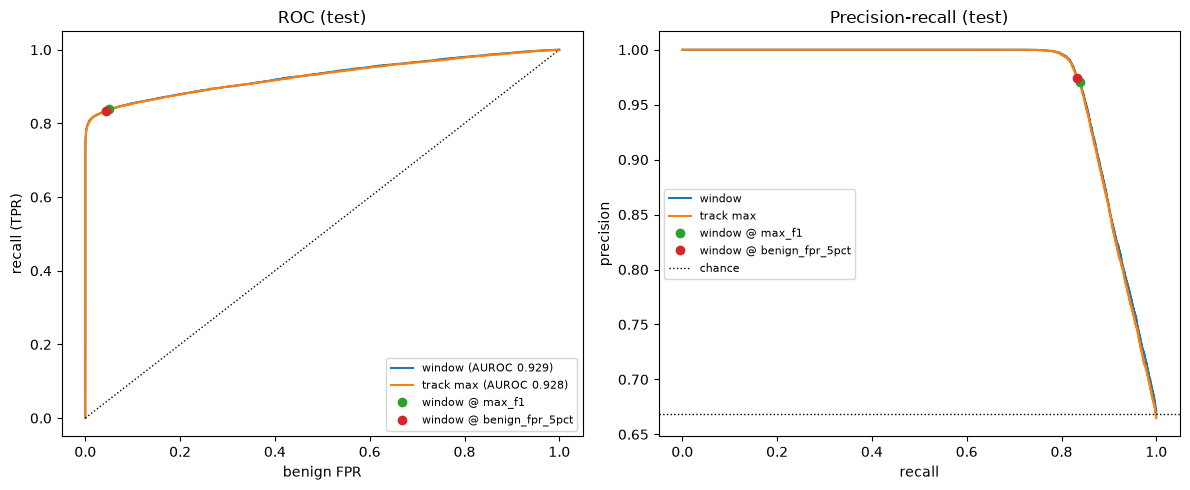

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
for level in ("window", "track max"):
    y, s, _ = levels[level]
    fpr, tpr, _ = roc_curve(y, s)
    p, r, _ = precision_recall_curve(y, s)
    a1.plot(fpr, tpr, label=f"{level} (AUROC {roc_auc_score(y, s):.3f})")
    a2.plot(r, p, label=level)
for name, v in THR["window"].items():
    m = threshold_metrics(y_win, test_out["prob"], v["threshold"])
    a1.plot(m["benign_fpr"], m["recall"], "o", label=f"window @ {name}")
    a2.plot(m["recall"], m["precision"], "o", label=f"window @ {name}")
a1.plot([0, 1], [0, 1], "k:", lw=1)
a1.set_xlabel("benign FPR")
a1.set_ylabel("recall (TPR)")
a1.legend(fontsize=8)
a2.axhline(y_win.mean(), color="k", ls=":", lw=1, label="chance")
a2.set_xlabel("recall")
a2.set_ylabel("precision")
a2.legend(fontsize=8)
a1.set_title("ROC (test)")
a2.set_title("Precision-recall (test)")
fig.tight_layout()
plt.show()

Test probability histogram by class, with the two val thresholds.

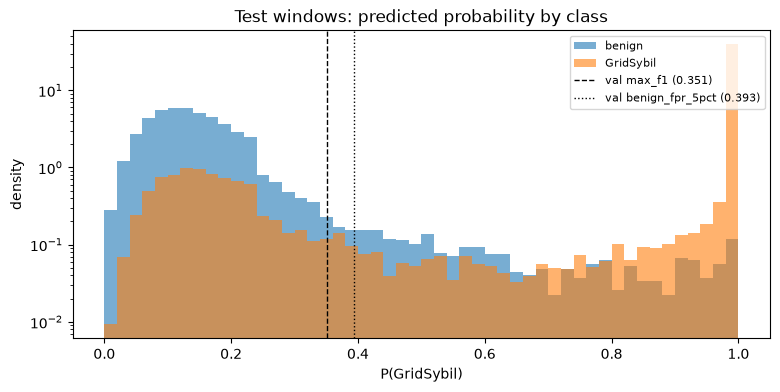

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 51)
ax.hist(test_out["prob"][y_win == 0], bins=bins, alpha=0.6, density=True, label="benign")
ax.hist(test_out["prob"][y_win == 1], bins=bins, alpha=0.6, density=True, label="GridSybil")
for (name, v), ls in zip(THR["window"].items(), ("--", ":")):
    ax.axvline(v["threshold"], color="black", ls=ls, lw=1, label=f"val {name} ({v['threshold']:.3f})")
ax.set_yscale("log")
ax.set_xlabel("P(GridSybil)")
ax.set_ylabel("density")
ax.legend(fontsize=8)
ax.set_title("Test windows: predicted probability by class")
plt.show()

Test AUROC by window length (real messages): a check that the classifier is not only reading the length (length-only
AUROC per group for reference).

In [14]:
groups = [(1, 3), (4, 16), (17, 47), (48, 48)]
rows = []
for lo, hi in groups:
    s = (test.n_messages >= lo) & (test.n_messages <= hi)
    y = y_win[s]
    rows.append(
        {
            "real rows": f"{lo}-{hi}",
            "windows": int(s.sum()),
            "GridSybil share": round(y.mean(), 3),
            "AUROC": roc_auc_score(y, test_out["prob"][s]),
            "length-only AUROC (best direction)": (
                max(roc_auc_score(y, test.n_messages[s]), 1 - roc_auc_score(y, test.n_messages[s]))
                if lo != hi
                else float("nan")
            ),
        }
    )
print(
    "length-only AUROC, all test windows (best direction):",
    round(max(roc_auc_score(y_win, test.n_messages), 1 - roc_auc_score(y_win, test.n_messages)), 4),
)
pd.DataFrame(rows).set_index("real rows").round(4)

length-only AUROC, all test windows (best direction): 0.5304


,windows,GridSybil share,AUROC,length-only AUROC (best direction)
real rows,,,,
1-3,6849,0.730,0.9170,0.5057
4-16,16468,0.666,0.9252,0.5361
17-47,12497,0.628,0.9249,0.5070
48-48,4655,0.700,0.9523,NaN


Mean per-feature reconstruction error by class on the test windows, and the per-feature AUROC of that error.

In [15]:
ef = test_out["error_feature"]
print(
    f"mean window reconstruction error: benign {test_out['error'][y_win == 0].mean():.4f}, "
    f"GridSybil {test_out['error'][y_win == 1].mean():.4f}; AUROC of the error {roc_auc_score(y_win, test_out['error']):.4f}"
)
pd.DataFrame(
    {
        "benign": ef[y_win == 0].mean(0),
        "GridSybil": ef[y_win == 1].mean(0),
        "AUROC": [roc_auc_score(y_win, ef[:, j]) for j in range(ef.shape[1])],
    },
    index=FEATURES,
).round(4).sort_values("AUROC", ascending=False)

mean window reconstruction error: benign 0.1517, GridSybil 0.1424; AUROC of the error 0.4780


,benign,GridSybil,AUROC
range,0.0225,0.0609,0.6427
log_dtau,0.1723,0.3208,0.6258
claimed_pos_y,0.0163,0.0416,0.6073
claimed_pos_x,0.0191,0.0428,0.5680
bearing,0.1463,0.1916,0.5408
rx_pos_y,0.0230,0.0291,0.5160
rx_pos_x,0.0229,0.0258,0.5025
rx_vel_y,0.1201,0.1079,0.4704
claimed_acl_y,0.4631,0.4377,0.4654
rx_vel_x,0.1382,0.1228,0.4611


2-D PCA of the test latent z, coloured by class (z is now shaped by the classifier loss as well).

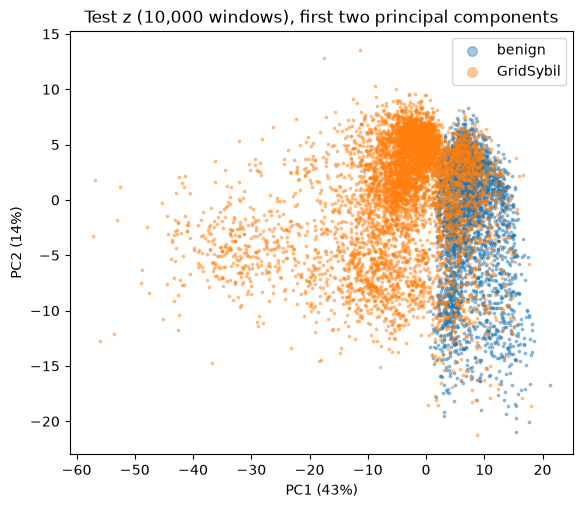

In [16]:
rng = np.random.default_rng(0)
sub = rng.choice(len(y_win), size=min(10000, len(y_win)), replace=False)
pca = PCA(2, random_state=0).fit(test_out["z"])
zz = pca.transform(test_out["z"][sub])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for cls, name in [(0, "benign"), (1, "GridSybil")]:
    s = y_win[sub] == cls
    ax.scatter(zz[s, 0], zz[s, 1], s=3, alpha=0.4, label=name)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=4)
ax.set_title("Test z (10,000 windows), first two principal components")
plt.show()

## 5. Comparison (context only)

Window-level test AUROC of earlier runs. The setups differ (data cut, T, split, seeds), so these rows are context,
not a controlled comparison: `task/autoencoder` (unsupervised, T48, no overlap, one seed), `task/autoencoder_overlap`
(unsupervised, T48_tvt_s24, one seed; numbers from its README), and `task/encoder` supervised encoder + head (T64,
90 / 10 split, 3 seeds; read from `task/encoder/runs/evaluation/results.json` when present).

In [17]:
w = res[(res.level == "window")].iloc[0]
cmp = [
    {
        "run": f"this run ({RUN.name}): supervised AE + head, T48_tvt",
        "score": "P(GridSybil)",
        "seeds": 1,
        "AUROC": w.auroc,
        "PR-AUC": w.pr_auc,
    }
]
cmp += [
    {
        "run": "task/autoencoder seed0: unsupervised AE, T48",
        "score": "reconstruction error",
        "seeds": 1,
        "AUROC": 0.484,
        "PR-AUC": 0.661,
    },
    {
        "run": "task/autoencoder_overlap seed0: unsupervised AE, T48_tvt_s24",
        "score": "reconstruction error",
        "seeds": 1,
        "AUROC": 0.484,
        "PR-AUC": 0.664,
    },
    {
        "run": "task/autoencoder_overlap seed0: unsupervised AE, T48_tvt_s24",
        "score": "Mahalanobis on z",
        "seeds": 1,
        "AUROC": 0.337,
        "PR-AUC": 0.595,
    },
]
enc = Path("task/encoder/runs/evaluation/results.json")
if enc.is_file():
    m = json.loads(enc.read_text())["methods"]["supervised:supervised_prob"]["summary"]
    cmp.append(
        {
            "run": "task/encoder: supervised encoder + head, T64",
            "score": "P(GridSybil)",
            "seeds": m["auroc"]["n"],
            "AUROC": m["auroc"]["mean"],
            "PR-AUC": m["pr_auc"]["mean"],
        }
    )
else:
    cmp.append(
        {
            "run": "task/encoder: supervised encoder + head, T64 (results.json missing; README value)",
            "score": "P(GridSybil)",
            "seeds": 3,
            "AUROC": 0.928,
            "PR-AUC": float("nan"),
        }
    )
pd.DataFrame(cmp).set_index("run").round(3)

,score,seeds,AUROC,PR-AUC
run,,,,
"this run (seed0): supervised AE + head, T48_tvt",P(GridSybil),1,0.929,0.971
"task/autoencoder seed0: unsupervised AE, T48",reconstruction error,1,0.484,0.661
"task/autoencoder_overlap seed0: unsupervised AE, T48_tvt_s24",reconstruction error,1,0.484,0.664
"task/autoencoder_overlap seed0: unsupervised AE, T48_tvt_s24",Mahalanobis on z,1,0.337,0.595
"task/encoder: supervised encoder + head, T64",P(GridSybil),3,0.928,0.970


The numbers the analysis below refers to.

In [18]:
results = {
    "run": RUN.name,
    "params": summary["params"],
    "best_epoch": summary["best_epoch"],
    "best_val_auroc": round(summary["best_val_auroc"], 4),
    "epochs_run": summary["epochs_run"],
    "stop_reason": summary["stop_reason"],
    "lr_changes": len(summary["lr_changes"]),
    "train_minutes": round(summary["train_seconds"] / 60, 1),
    "mixed_label_tracks": mixed,
}
for _, r in res.iterrows():
    results[f"{r.level}/{r.threshold}"] = {
        k: round(float(r[k]), 4)
        for k in ("auroc", "pr_auc", "θ", "precision", "recall", "f1", "balanced_accuracy", "benign_fpr")
    }
results

{'run': 'seed0',
 'params': 72318,
 'best_epoch': 44,
 'best_val_auroc': 0.9268,
 'epochs_run': 54,
 'stop_reason': 'early_stopping',
 'lr_changes': 3,
 'train_minutes': 5.5,
 'mixed_label_tracks': 0,
 'window/max_f1': {'auroc': 0.9289,
  'pr_auc': 0.971,
  'θ': 0.3507,
  'precision': 0.9708,
  'recall': 0.8387,
  'f1': 0.9,
  'balanced_accuracy': 0.8939,
  'benign_fpr': 0.0509},
 'window/benign_fpr_5pct': {'auroc': 0.9289,
  'pr_auc': 0.971,
  'θ': 0.3932,
  'precision': 0.9745,
  'recall': 0.8334,
  'f1': 0.8984,
  'balanced_accuracy': 0.8947,
  'benign_fpr': 0.044},
 'window/fixed 0.5': {'auroc': 0.9289,
  'pr_auc': 0.971,
  'θ': 0.5,
  'precision': 0.9824,
  'recall': 0.8267,
  'f1': 0.8979,
  'balanced_accuracy': 0.8984,
  'benign_fpr': 0.0299},
 'track max/max_f1': {'auroc': 0.9277,
  'pr_auc': 0.9702,
  'θ': 0.3507,
  'precision': 0.9673,
  'recall': 0.8403,
  'f1': 0.8994,
  'balanced_accuracy': 0.892,
  'benign_fpr': 0.0563},
 'track max/benign_fpr_5pct': {'auroc': 0.9277,
  '

## 6. Analysis

Numbers from the outputs above (run `seed0`, one seed, no confidence intervals).

- **Training converged quickly and stopped on val.** Val AUROC was 0.899 at epoch 1 (high but not ~1.0; the inputs
  are x + mask only) and rose to a best of **0.9268 at epoch 44**; early stopping (patience 10, min_delta 1e-4
  absolute) ended the run at epoch 54 after 3 LR halvings (1e-3 to 1.25e-4), 5.5 min on MPS. At the best epoch the
  running train AUROC was 0.944 vs val 0.927 (train measured in train mode, so the gap is only indicative): a small
  generalisation gap. Val BCE flattened at about 0.20 from epoch 20 (minimum 0.195 at epoch 37) while train BCE kept falling (0.189 to
  0.164 by epoch 54), so later epochs mostly fit train; val AUROC still crept up by about 0.006. One batch hit a
  pre-clip gradient norm of 17.0 (epoch 23; clipped to 1.0); the mean norm stayed near 0.5. Val masked MSE ended at 0.159, a little
  above the unsupervised overlap autoencoder (0.143), so the BCE term costs some reconstruction but does not break it.
- **Test, per window:** AUROC **0.929**, PR-AUC **0.971** (chance 0.669). At the val max-F1 threshold (θ = 0.351):
  precision 0.971, recall 0.839, F1 **0.900**, balanced accuracy 0.894, benign FPR 0.051. At the val benign-FPR-5%
  threshold (θ = 0.393): benign FPR 0.044 (nominal 0.05), recall 0.833, F1 0.898. Both val thresholds carry over to
  test within about one point of FPR. About 16% of GridSybil test windows are missed at either threshold.
- **Per track** (35,957 test tracks for 40,469 windows, no track with mixed labels): AUROC 0.928 (max) / 0.929
  (mean), F1 about 0.90; most tracks hold one window, so aggregation changes little.
- **Not a length shortcut:** length alone gives AUROC 0.530 on test. The model reaches 0.917 even on windows with 1-3
  real rows and 0.952 on full 48-row windows; shorter windows are harder but still well separated.
- **The head does the detecting, not the reconstruction error.** The window reconstruction error alone has AUROC
  0.478 (as in the unsupervised runs). Per feature, GridSybil is rebuilt worse on range, log-Δτ and claimed position
  (AUROC 0.57-0.64) and much better on claimed velocity (0.25); these cancel in the mean error, while the classifier
  reads the class from z.
- **Context (different setups, not controlled):** the result matches the `task/encoder` supervised encoder + head at
  T = 64 (0.928, 3 seeds) and is far above the unsupervised T48 autoencoders (0.484 reconstruction, 0.337
  Mahalanobis). With labels, a 72k-parameter model separates benign from GridSybil well; without them the same
  architecture does not.
- **Limits:** one seed; windows from the same sender vehicle are not independent (574 test vehicles), so no CI is
  claimed. The model is trained and tested on GridSybil only, so it says nothing about unseen attacks (e.g. the
  held-out DataReplay). Track ids contain the true sender, which separates ghosts that share pseudonym 1 (F13): the
  track level is a privileged grouping. Not the thesis TimesNet model and not a thesis result.